In [124]:
import torch
import torch.nn.functional as f
import matplotlib.pyplot as plt
%matplotlib inline

In [125]:
words = open('names.txt','r').read().splitlines()
words[:4]

['emma', 'olivia', 'ava', 'isabella']

In [126]:
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
vocab_size

27

In [127]:
block_size = 3
def dataset(words):

    X,y = [],[]
    for w in words:
        context = [0]*3
        ch = w+'.'
        for c in ch:
            ix = stoi[c]
            X.append(context)
            y.append(ix)
            context=context[1:]+[ix]
            if ix==0:
                break
    
    X = torch.tensor(X) 
    y = torch.tensor(y) 
    print(X.shape,y.shape)
    return X,y

import random
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, ytr = dataset(words[:n1])
Xdev,ydev = dataset(words[n1:n2])
Xte,yte = dataset(words[n2:])

torch.Size([182535, 3]) torch.Size([182535])
torch.Size([22890, 3]) torch.Size([22890])
torch.Size([22721, 3]) torch.Size([22721])


In [128]:
n_emb = 10
n_hidden = 200

g = torch.Generator().manual_seed(3)
C = torch.randn((vocab_size,n_emb),generator=g)  
W1 = torch.randn((n_emb*block_size, n_hidden), generator=g)  * (5/3)/((n_emb*block_size)**0.5)
b1 = torch.randn((n_hidden,), generator=g)  *0.01
W2 = torch.randn((n_hidden, vocab_size),generator=g)  *0.01
b2 = torch.randn((vocab_size,),generator=g)  *0.1
bngain= torch.ones((1,n_hidden)) 
bnbias = torch.zeros((1,n_hidden)) 
bnmean_running = torch.zeros((1,n_hidden)) 
bnstd_running = bnbias = torch.ones((1,n_hidden)) 

parameters = [C,W1,b1,W2,b2, bnbias, bngain]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad=True
    

12297


In [160]:
max_steps = 200_000
batch_size = 32
lossi=[]

for i in range(max_steps):
    ix = torch.randint(0,Xtr.shape[0], (batch_size,), generator=g) 
    Xb,yb = Xtr[ix], ytr[ix]
    
    emb = C[Xb]
    embcat = emb.view(emb.shape[0],-1)
    h_ = embcat@W1 
    bnmeani = h_.mean(0,keepdim=True)
    bnstdi = h_.std(0,keepdim=True)
    h_ = (bngain*(h_-bnmeani)/bnstdi)+ bnbias

    with torch.no_grad():
        bnmean_running = 0.999*bnmean_running+0.001*bnmeani
        bnstd_running = 0.999*bnstd_running+0.001*bnstdi

    h = torch.tanh(h_)
    logits = h@W2+b2
    loss = f.cross_entropy(logits,yb)

    for p in parameters:
        p.grad=None
    loss.backward()

    lr = 0.1 if i<100_000 else 0.01
    for p in parameters:
        p.data +=-lr*p.grad

    if i%10000==0:
        print(f'{i}/{max_steps}: {loss.item():.4f}')
    lossi.append(loss.log10().item())


TypeError: unsupported operand type(s) for *: 'float' and 'NoneType'

In [130]:
bngain, bnmean_running

(tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1.]], requires_grad=True),
 tensor([[ 5.8984e-04, -7.4536e-04, -4.8517e-05,  6.5736e

In [131]:
@torch.no_grad()
def split_loss(split):
    x,y = {
        'train':[Xtr,ytr],
        "val":[Xdev,ydev],
        'test':[Xte,yte]
    }[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0],-1)
    h_ = embcat@W1+b1
    h_ = (bngain*(h_-h_.mean(0,keepdim=True))/h_.std(0,keepdim=True))+ bnbias
    h = torch.tanh(h_)
    logits = h@W2+b2
    loss = f.cross_entropy(logits,y)
    print(split, loss.item())

split_loss('train')
split_loss('test')



train 3.332144260406494
test 3.3324520587921143


In [159]:
g = torch.Generator().manual_seed(3)
for _ in range(20):
    out = []
    context = [0]*block_size
    while True:
        emb = C[torch.tensor([context]) ]
        h = torch.tanh(emb.view(1,-1)@W1+b1) 
        logits = h@W2+b2
        probs = f.softmax(logits, dim=1)
        ix = torch.multinomial(probs,num_samples=1,generator=g) .item()
        context = context[1:]+[ix]
        out.append(ix)
        if ix==0:
            break

    print("".join(itos[i] for i in out))

.
ehdavzjacgaacwevohncdimdrwsibe.
itnzxhnqlbjxqwtewxoeczlktmycelicq.
.
eaqz.
kihdyfnjfgzrbmppbymqxacrrraxfzvqjkffzhbviemyluoglukdnwhftyccrkwk.
nhzmygcchbrdlzarcqvoefkkaiidhpzimjhdrzqvgmgqsugzsrpbiigukpgvegtzytwjeorttbogndlukhqomvwxdyrlpllhinrwzfyabanapdfnsfyvvqplinryyvpkptnuj.
z.
sbojnvsandhngrfp.
urkkwnigszoflwhfktwawqbjhcnmonaclhpyjeytqxlumwybjeekorscgpggftcwansucov.
pywxxrau.
gmubtuzkprojwbeukpxgeuqfagcelxlptmeyhfuekvnwq.
omcwkjzyahzopccvbpygajyhjqbhsgdj.
kvdwctjcawoomczchmleexrjqcbidbokjqbfluhyioqhloaimmzkhyryxuynplwyphkfihylorwvlthdnlkksnfuezpkgrxtilpzdoueieqzcyuguoizbxryhqvjnthunpivnnkdijucgtacfzzvjnccfcxzyiicpvkehbxoymumdpfwmxmsheuzwrbdewqcckbsgptozylxkqlrzwfgsrxqbgucfhioowyjewqckzxwedvpobg.
.
twdvelyeqxebtiudlptbiwndvvyzvnprjcaupnzzbqikzmlyhf.
ulxnctotjixhpkznnwxrxqktfuexrbhrmrkckmdoofyqb.
iyt.
rboksofvqeynbarwqwqmtfgshs.
sfiewrhexaatbclkkinjksrj.


In [170]:
g = torch.Generator().manual_seed(2)

class Linear:
    def __init__(self,fan_in,fan_out, bias=True):
        self.weight = torch.randn((fan_in,fan_out), generator = g)/fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self,x):
        self.out = x@self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    
    def parameters(self):
        return [self.weight]+ ([] if self.bias is None else [self.bias])

class BatchNorm1D:
    def __init__(self,dim,esp=1e-5,momentum=0.1):
        self.eps = esp
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.running_var = torch.ones(dim)
        self.running_mean = torch.zeros(dim)

    def __call__(self,x):
        if self.training:
            xmean = x.mean(0,keepdim=True)
            xvar = x.var(0,keepdim=True)

        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = x.var(0,keepdim=True, unbiased=True)
        xhat_ = (x - xmean) / torch.sqrt(xvar + self.eps)
        self.out = self.gamma * xhat_ + self.beta

        if self.training:
            self.running_var = (1-self.momentum)*self.running_var+self.momentum*xvar
            self.running_mean = (1-self.momentum)*self.running_mean+self.momentum*xmean

        return self.out

    def parameters(self):
        return [self.gamma,self.beta]

class Tanh:
    def __call__(self,x):
        self.out = torch.tanh(x)
        return self.out
    
    def parameters(self):
        return []


n_embd = 10
n_hidden = 100
g = torch.Generator().manual_seed(2)
C = torch.randn((vocab_size,n_embd),generator=g)
layers = [Linear(n_embd*block_size , n_hidden),BatchNorm1D(n_hidden), Tanh(), 
        Linear(n_hidden,n_hidden),BatchNorm1D(n_hidden), Tanh(),
         Linear(n_hidden,n_hidden),BatchNorm1D(n_hidden), Tanh(),
          Linear(n_hidden,n_hidden),BatchNorm1D(n_hidden), Tanh(),
         Linear(n_hidden,n_hidden),BatchNorm1D(n_hidden), Tanh(),
         Linear(n_hidden,vocab_size),BatchNorm1D(vocab_size),]

with torch.inference_mode():
    layers[-1].gamma*=0.1
    for layer in layers[:-1]:
        if isinstance(layer,Linear):
            layer.weight*=1

parameters = [C]+[p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters ))
for p in parameters:
    p.requires_grad=True



47551


In [173]:
max_steps = 200_000
batch_size=32
lossi=[]
for i in range(max_steps):
    ix=torch.randint(0,Xtr.shape[0], (batch_size,), generator=g)
    Xb,Yb = Xtr[ix],ytr[ix]

    emb = C[Xb]
    x = emb.view(emb.shape[0],-1)
    for layer in layers:
        x=layer(x)

    loss = f.cross_entropy(x,Yb)

    for layer in layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad=None
    loss.backward()

    lr = 0.1

    for p in parameters:
        p.data+=-lr*p.grad


    if i%10_000==0:
        print(f"{i}=> {loss.item():.4f}")
    lossi.append(loss.log10().item())


0=> 1.7600
10000=> 2.2174
20000=> 2.1286
30000=> 2.3039
40000=> 2.1111
50000=> 2.0175
60000=> 2.1571
70000=> 2.3391
80000=> 1.8460
90000=> 2.2922
100000=> 2.3001
110000=> 1.8986
120000=> 1.5388
130000=> 1.6466
140000=> 1.6579
150000=> 2.1346
160000=> 1.9602
170000=> 1.6778
180000=> 1.6790
190000=> 2.0799


tensor(19.7188) tensor(0.0002, grad_fn=<MeanBackward0>) tensor(0.6733, grad_fn=<StdBackward0>)
tensor(23.5312) tensor(-0.0243, grad_fn=<MeanBackward0>) tensor(0.7386, grad_fn=<StdBackward0>)
tensor(26.0625) tensor(0.0156, grad_fn=<MeanBackward0>) tensor(0.7856, grad_fn=<StdBackward0>)
tensor(28.6562) tensor(0.0151, grad_fn=<MeanBackward0>) tensor(0.8126, grad_fn=<StdBackward0>)
tensor(37.7188) tensor(-0.0022, grad_fn=<MeanBackward0>) tensor(0.8492, grad_fn=<StdBackward0>)


Text(0.5, 1.0, 'ad')

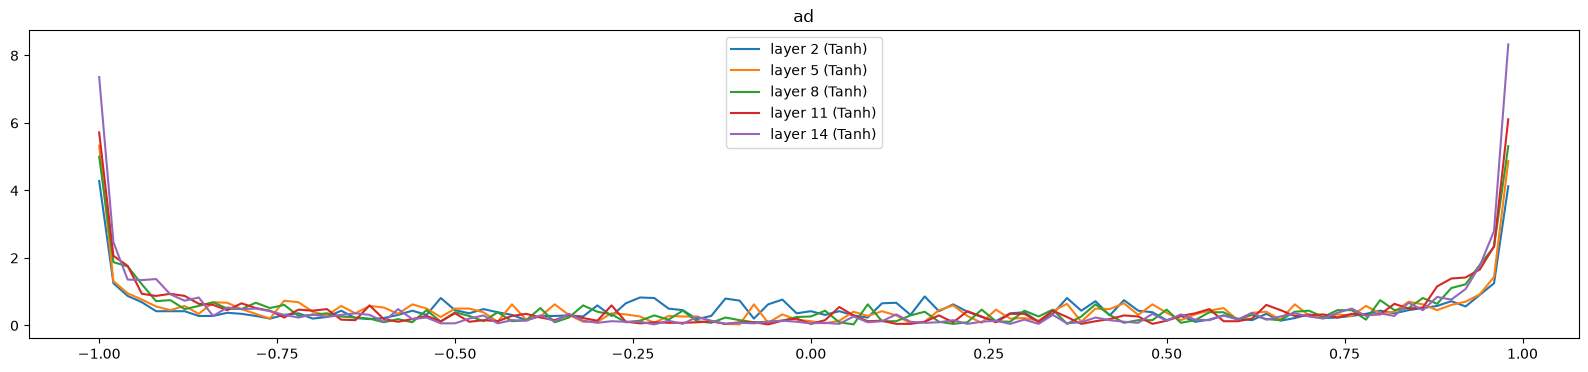

In [174]:
plt.figure(figsize=(20,4))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer,Tanh):
        t = layer.out
        print((t.abs()>0.97).float().mean()*100, t.mean(), t.std())
        hy,hx = torch.histogram(t,density=True)
        plt.plot(hx[:-1].detach(),hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('ad')

In [ ]:
block_size = 3
def dataset(words):

    X,y = [],[]
    for w in words:
        context = [0]*3
        ch = w+'.'
        for c in ch:
            ix = stoi[c]
            X.append(context)
            y.append(ix)
            context=context[1:]+[ix]
            if ix==0:
                break
    
    X = torch.tensor(X) 
    y = torch.tensor(y) 
    print(X.shape,y.shape)
    return X,y

import random
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, ytr = dataset(words[:n1])
Xdev,ydev = dataset(words[n1:n2])
Xte,yte = dataset(words[n2:])